# Modelos com faixas etárias agrupadas: busca de hiperparâmetros

Compara vários classificadores com `GridSearchCV` no problema com as faixas etárias agrupadas, o mesmo da parte 2 de `model.ipynb`. Usa os conjuntos gerados por `data_preparation.ipynb`, sem alterá-los: só o alvo `y` é recalculado a partir da coluna `AGE`, com os grupos definidos em `Config.AGE_GROUPS`.

In [1]:
class Config:
    RANDOM_STATE = 42
    MAX_RAM_GB = 12
    N_JOBS = 4
    N_SELECTED_GENES = 500
    SCORING = "f1_macro"
    MISCLASSIFIED_WEIGHT = 2
    ERROR_CV_FOLDS = 5
    AGE_GROUPS = {
        "20-49": ["20-29", "30-39", "40-49"],
        "50-59": ["50-59"],
        "60-79": ["60-69", "70-79"],
    }

In [2]:
import resource

max_bytes = Config.MAX_RAM_GB * 1024**3
resource.setrlimit(resource.RLIMIT_AS, (max_bytes, max_bytes))

import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler

from src.data.loader import load_splits

In [3]:
GROUP_LABELS = {code: group for code, group in enumerate(Config.AGE_GROUPS, start=1)}
AGE_TO_GROUP = {age: code for code, ages in enumerate(Config.AGE_GROUPS.values(), start=1) for age in ages}

splits = load_splits()
X_train, _, info_train = splits["train"]
X_val, _, info_val = splits["val"]
X_test, _, info_test = splits["test"]

y_train = info_train["AGE"].map(AGE_TO_GROUP).astype(int)
y_val = info_val["AGE"].map(AGE_TO_GROUP).astype(int)
y_test = info_test["AGE"].map(AGE_TO_GROUP).astype(int)

pd.DataFrame({name: X.shape for name, (X, y, info) in splits.items()}, index=["Amostras", "Genes"])

,train,val,test
Amostras,1853,658,315
Genes,17500,17500,17500


## Alvo: grupos de idade

Cada faixa etária original recebe o código do seu grupo: 1 para o primeiro grupo de `Config.AGE_GROUPS`, 2 para o segundo e assim por diante. As amostras sintéticas do treino recebem o grupo da faixa da amostra que as gerou.

In [4]:
GROUP_LABELS

{1: '20-49', 2: '50-59', 3: '60-79'}

In [5]:
counts = pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "val": y_val.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
})
counts.index = [f"{code} ({GROUP_LABELS[code]})" for code in counts.index]
counts.rename_axis("Grupo de idade")

,train,val,test
Grupo de idade,,,
1 (20-49),554,100,35
2 (50-59),455,187,101
3 (60-79),844,371,179


## Peso maior nas amostras que o modelo erra

Para que o modelo priorize as amostras que ele erra, cada modelo é treinado em duas etapas, a mesma ideia do boosting:

1. Descobrir quais amostras de treino o modelo erra. Para isso, o treino é dividido em `ERROR_CV_FOLDS` partes por doador (`StratifiedGroupKFold`), e cada amostra é classificada por um modelo treinado sem ela. Testar no próprio treino não funcionaria, porque modelos como a árvore e o KNN com k = 1 quase não erram os dados que já viram. A divisão por doador mantém juntas as amostras de uma pessoa e as suas cópias sintéticas.
2. Treinar o modelo de novo com peso `MISCLASSIFIED_WEIGHT` nas amostras erradas e peso 1 nas demais (`sample_weight`). O KNN não aceita pesos, então nele as amostras erradas são duplicadas no treino.

Os resultados mostram o modelo sem peso e com peso, para comparação.

In [6]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline

groups_train = info_train["SUBJID"]


def misclassified_weights(model, X, y, groups, weight=Config.MISCLASSIFIED_WEIGHT):
    cv = StratifiedGroupKFold(n_splits=Config.ERROR_CV_FOLDS, shuffle=True, random_state=Config.RANDOM_STATE)
    predicted = cross_val_predict(clone(model), X, y, groups=groups, cv=cv, n_jobs=Config.N_JOBS)
    return np.where(predicted != np.asarray(y), weight, 1)


def fit_weighted(model, X, y, weights):
    model = clone(model)
    step_name, classifier = model.steps[-1] if isinstance(model, Pipeline) else (None, model)
    if isinstance(classifier, KNeighborsClassifier):
        rows = np.repeat(np.arange(len(X)), weights)
        return model.fit(X.iloc[rows], y.iloc[rows])
    if step_name:
        return model.fit(X, y, **{f"{step_name}__sample_weight": weights})
    return model.fit(X, y, sample_weight=weights)


def compare_weighting(model, X, y, groups, X_eval, label_offset=0):
    y_fit = y - label_offset
    plain = clone(model).fit(X, y_fit).predict(X_eval) + label_offset
    weights = misclassified_weights(model, X, y_fit, groups)
    weighted = fit_weighted(model, X, y_fit, weights).predict(X_eval) + label_offset
    return plain, weighted, weights

## Métricas

F1 de cada grupo, F1 macro, acurácia, acerto com tolerância de 1 grupo e erro médio em grupos.

In [7]:
def evaluate(y_true, y_pred):
    classes = sorted(GROUP_LABELS)
    distance = np.abs(np.asarray(y_pred) - np.asarray(y_true))
    per_class = pd.Series(f1_score(y_true, y_pred, labels=classes, average=None, zero_division=0) * 100,
                          index=[f"{code} ({GROUP_LABELS[code]})" for code in classes])
    summary = pd.Series({
        "F1 macro": f1_score(y_true, y_pred, labels=classes, average="macro", zero_division=0) * 100,
        "Acurácia": accuracy_score(y_true, y_pred) * 100,
        "Acerto com tolerância de 1 grupo": (distance <= 1).mean() * 100,
        "Erro médio em grupos": distance.mean(),
    })
    return pd.concat([per_class, summary]).round(2)

## Busca de hiperparâmetros com vários modelos (GridSearchCV)

Cada modelo é um `Pipeline` com três etapas, ajustadas só nos dados de treino de cada rodada:

1. `SelectKBest` (aula da semana 11): mantém os `N_SELECTED_GENES` genes com maior pontuação ANOVA (`f_classif`) em relação ao grupo de idade. Com 17500 genes, a busca seria lenta demais e consumiria muita memória.
2. `StandardScaler` (aula da semana 10).
3. O classificador.

A busca usa a validação já separada (`PredefinedSplit`), e não uma validação cruzada dentro do treino. Assim, uma amostra e suas cópias sintéticas, ou duas amostras do mesmo doador, nunca ficam uma no treino e outra na avaliação. A métrica é o F1 macro.

Para não travar o computador, a memória do notebook é limitada por `MAX_RAM_GB` e o número de processos em paralelo por `N_JOBS`, os dois definidos na `Config`. O XGBoost exige rótulos a partir de 0, então todos os modelos são treinados com o código do grupo menos 1 e as previsões são convertidas de volta.

A grade completa de hiperparâmetros está comentada na célula abaixo. A grade ativa contém só a melhor configuração de cada modelo encontrada na busca completa com as 6 faixas etárias, para o notebook rodar rápido. Com os grupos de idade, a melhor configuração pode ser outra, então vale refazer a busca completa ao menos uma vez. Para refazer a busca completa, descomente a grade completa e comente a grade com as melhores configurações.

Os hiperparâmetros são escolhidos sem pesos. Depois, a melhor configuração de cada modelo é treinada de novo com peso maior nas amostras erradas, como na seção acima, e as tabelas e matrizes de confusão mostram esses modelos com peso.

In [8]:
import xgboost as xgb
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV, PredefinedSplit, ParameterGrid
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC


def make_pipeline(classifier):
    return Pipeline([
        ("select", SelectKBest(f_classif, k=Config.N_SELECTED_GENES)),
        ("scaler", StandardScaler()),
        ("clf", classifier),
    ])


models = {
    "KNN": make_pipeline(KNeighborsClassifier()),
    "DecisionTree": make_pipeline(DecisionTreeClassifier(random_state=Config.RANDOM_STATE)),
    "NaiveBayes": make_pipeline(GaussianNB()),
    "MLP": make_pipeline(MLPClassifier(max_iter=1000, random_state=Config.RANDOM_STATE)),
    "SVM": make_pipeline(SVC(random_state=Config.RANDOM_STATE)),
    "RF": make_pipeline(RandomForestClassifier(random_state=Config.RANDOM_STATE, n_jobs=1)),
    "AdaBoost": make_pipeline(AdaBoostClassifier(random_state=Config.RANDOM_STATE)),
    "Bagging": make_pipeline(BaggingClassifier(random_state=Config.RANDOM_STATE, n_jobs=1)),
    "Xgboost": make_pipeline(xgb.XGBClassifier(objective="multi:softprob", tree_method="hist",
                                               random_state=Config.RANDOM_STATE, n_jobs=1)),
}

# param_grids = {
#     "KNN": {
#         "clf__n_neighbors": [1, 3, 5],
#         "clf__weights": ["uniform", "distance"],
#         "clf__p": [1, 2],
#     },
#     "DecisionTree": {
#         "clf__criterion": ["gini", "entropy", "log_loss"],
#         "clf__max_depth": [None, 5, 10, 20],
#         "clf__min_samples_split": [2, 5, 10],
#         "clf__min_samples_leaf": [1, 2, 4],
#     },
#     "NaiveBayes": {
#         "clf__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6, 1e-5],
#     },
#     "MLP": {
#         "clf__hidden_layer_sizes": [(8,), (20,), (16,), (16, 8), (15, 10)],
#         "clf__activation": ["relu", "tanh", "logistic"],
#         "clf__alpha": [1e-4, 1e-3, 1e-2],
#         "clf__learning_rate_init": [1e-3, 1e-2, 1e-1],
#     },
#     "SVM": {
#         "clf__C": [0.1, 1, 10, 20],
#         "clf__kernel": ["rbf", "linear", "poly"],
#         "clf__gamma": ["scale", "auto", 0.001],
#     },
#     "RF": {
#         "clf__n_estimators": [50, 100, 200],
#         "clf__max_depth": [None, 10, 20],
#     },
#     "AdaBoost": {
#         "clf__n_estimators": [50, 100, 200],
#         "clf__learning_rate": [0.1, 0.5, 1.0],
#     },
#     "Bagging": {
#         "clf__n_estimators": [50, 100, 200],
#         "clf__max_samples": [0.5, 0.75, 1.0],
#     },
#     "Xgboost": {
#         "clf__n_estimators": [50, 100, 200],
#         "clf__learning_rate": [0.1, 0.5, 1.0],
#     },
# }

param_grids = {
    "KNN": {"clf__n_neighbors": [1], "clf__p": [1], "clf__weights": ["uniform"]},
    "DecisionTree": {"clf__criterion": ["entropy"], "clf__max_depth": [5], "clf__min_samples_leaf": [1], "clf__min_samples_split": [2]},
    "NaiveBayes": {"clf__var_smoothing": [1e-9]},
    "MLP": {"clf__activation": ["logistic"], "clf__alpha": [0.001], "clf__hidden_layer_sizes": [(16,)], "clf__learning_rate_init": [0.1]},
    "SVM": {"clf__C": [10], "clf__gamma": [0.001], "clf__kernel": ["rbf"]},
    "RF": {"clf__max_depth": [None], "clf__n_estimators": [50]},
    "AdaBoost": {"clf__learning_rate": [1.0], "clf__n_estimators": [100]},
    "Bagging": {"clf__max_samples": [0.5], "clf__n_estimators": [200]},
    "Xgboost": {"clf__learning_rate": [1.0], "clf__n_estimators": [50]},
}

pd.Series({name: len(ParameterGrid(grid)) for name, grid in param_grids.items()}, name="Combinações testadas")

KNN             1
DecisionTree    1
NaiveBayes      1
MLP             1
SVM             1
RF              1
AdaBoost        1
Bagging         1
Xgboost         1
Name: Combinações testadas, dtype: int64

In [9]:
X_search = pd.concat([X_train, X_val])
y_search = pd.concat([y_train, y_val]) - 1
validation_split = PredefinedSplit([-1] * len(X_train) + [0] * len(X_val))

searches = {}
for name, model in models.items():
    search = GridSearchCV(model, param_grids[name], scoring=Config.SCORING, cv=validation_split,
                          refit=False, n_jobs=Config.N_JOBS)
    search.fit(X_search, y_search)
    searches[name] = search
    print(f"{name}: F1 macro na validação = {search.best_score_ * 100:.2f}% | {search.best_params_}")

KNN: F1 macro na validação = 37.60% | {'clf__n_neighbors': 1, 'clf__p': 1, 'clf__weights': 'uniform'}
DecisionTree: F1 macro na validação = 36.40% | {'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2}
NaiveBayes: F1 macro na validação = 32.61% | {'clf__var_smoothing': 1e-09}
MLP: F1 macro na validação = 43.02% | {'clf__activation': 'logistic', 'clf__alpha': 0.001, 'clf__hidden_layer_sizes': (16,), 'clf__learning_rate_init': 0.1}
SVM: F1 macro na validação = 49.32% | {'clf__C': 10, 'clf__gamma': 0.001, 'clf__kernel': 'rbf'}
RF: F1 macro na validação = 41.63% | {'clf__max_depth': None, 'clf__n_estimators': 50}
AdaBoost: F1 macro na validação = 44.24% | {'clf__learning_rate': 1.0, 'clf__n_estimators': 100}
Bagging: F1 macro na validação = 41.23% | {'clf__max_samples': 0.5, 'clf__n_estimators': 200}
Xgboost: F1 macro na validação = 45.64% | {'clf__learning_rate': 1.0, 'clf__n_estimators': 50}


In [10]:
best_predictions = {}
best_plain_predictions = {}
for name, search in searches.items():
    best_model = clone(models[name]).set_params(**search.best_params_)
    best_plain_predictions[name], best_predictions[name], _ = compare_weighting(
        best_model, X_train, y_train, groups_train, X_val, label_offset=1
    )

grid_results = pd.DataFrame({name: evaluate(y_val, pred) for name, pred in best_predictions.items()})
grid_results = grid_results[grid_results.loc["F1 macro"].sort_values(ascending=False).index]
display(grid_results.rename_axis(f"Com peso {Config.MISCLASSIFIED_WEIGHT} nos erros (validação, %)"))

pd.DataFrame({
    name: {
        "F1 macro sem peso": evaluate(y_val, best_plain_predictions[name])["F1 macro"],
        "F1 macro com peso": evaluate(y_val, best_predictions[name])["F1 macro"],
    }
    for name in grid_results.columns
})

,SVM,MLP,Xgboost,Bagging,RF,AdaBoost,KNN,NaiveBayes,DecisionTree
"Com peso 2 nos erros (validação, %)",,,,,,,,,
1 (20-49),47.19,44.71,37.07,35.39,35.34,37.38,23.76,30.42,22.22
2 (50-59),33.75,30.35,35.09,35.05,32.10,34.03,29.47,28.10,22.69
3 (60-79),62.08,64.35,65.80,64.42,65.00,60.28,57.77,48.16,61.17
F1 macro,47.67,46.47,45.99,44.95,44.15,43.90,37.00,35.56,35.36
Acurácia,51.52,52.28,53.34,51.67,51.67,48.94,44.38,37.84,46.05
Acerto com tolerância de 1 grupo,91.49,91.34,87.08,84.35,85.11,87.23,85.11,77.51,85.41
Erro médio em grupos,0.57,0.56,0.60,0.64,0.63,0.64,0.71,0.85,0.69


,SVM,MLP,Xgboost,Bagging,RF,AdaBoost,KNN,NaiveBayes,DecisionTree
F1 macro sem peso,49.32,38.60,45.64,41.23,41.63,44.24,37.6,32.61,36.40
F1 macro com peso,47.67,46.47,45.99,44.95,44.15,43.90,37.0,35.56,35.36


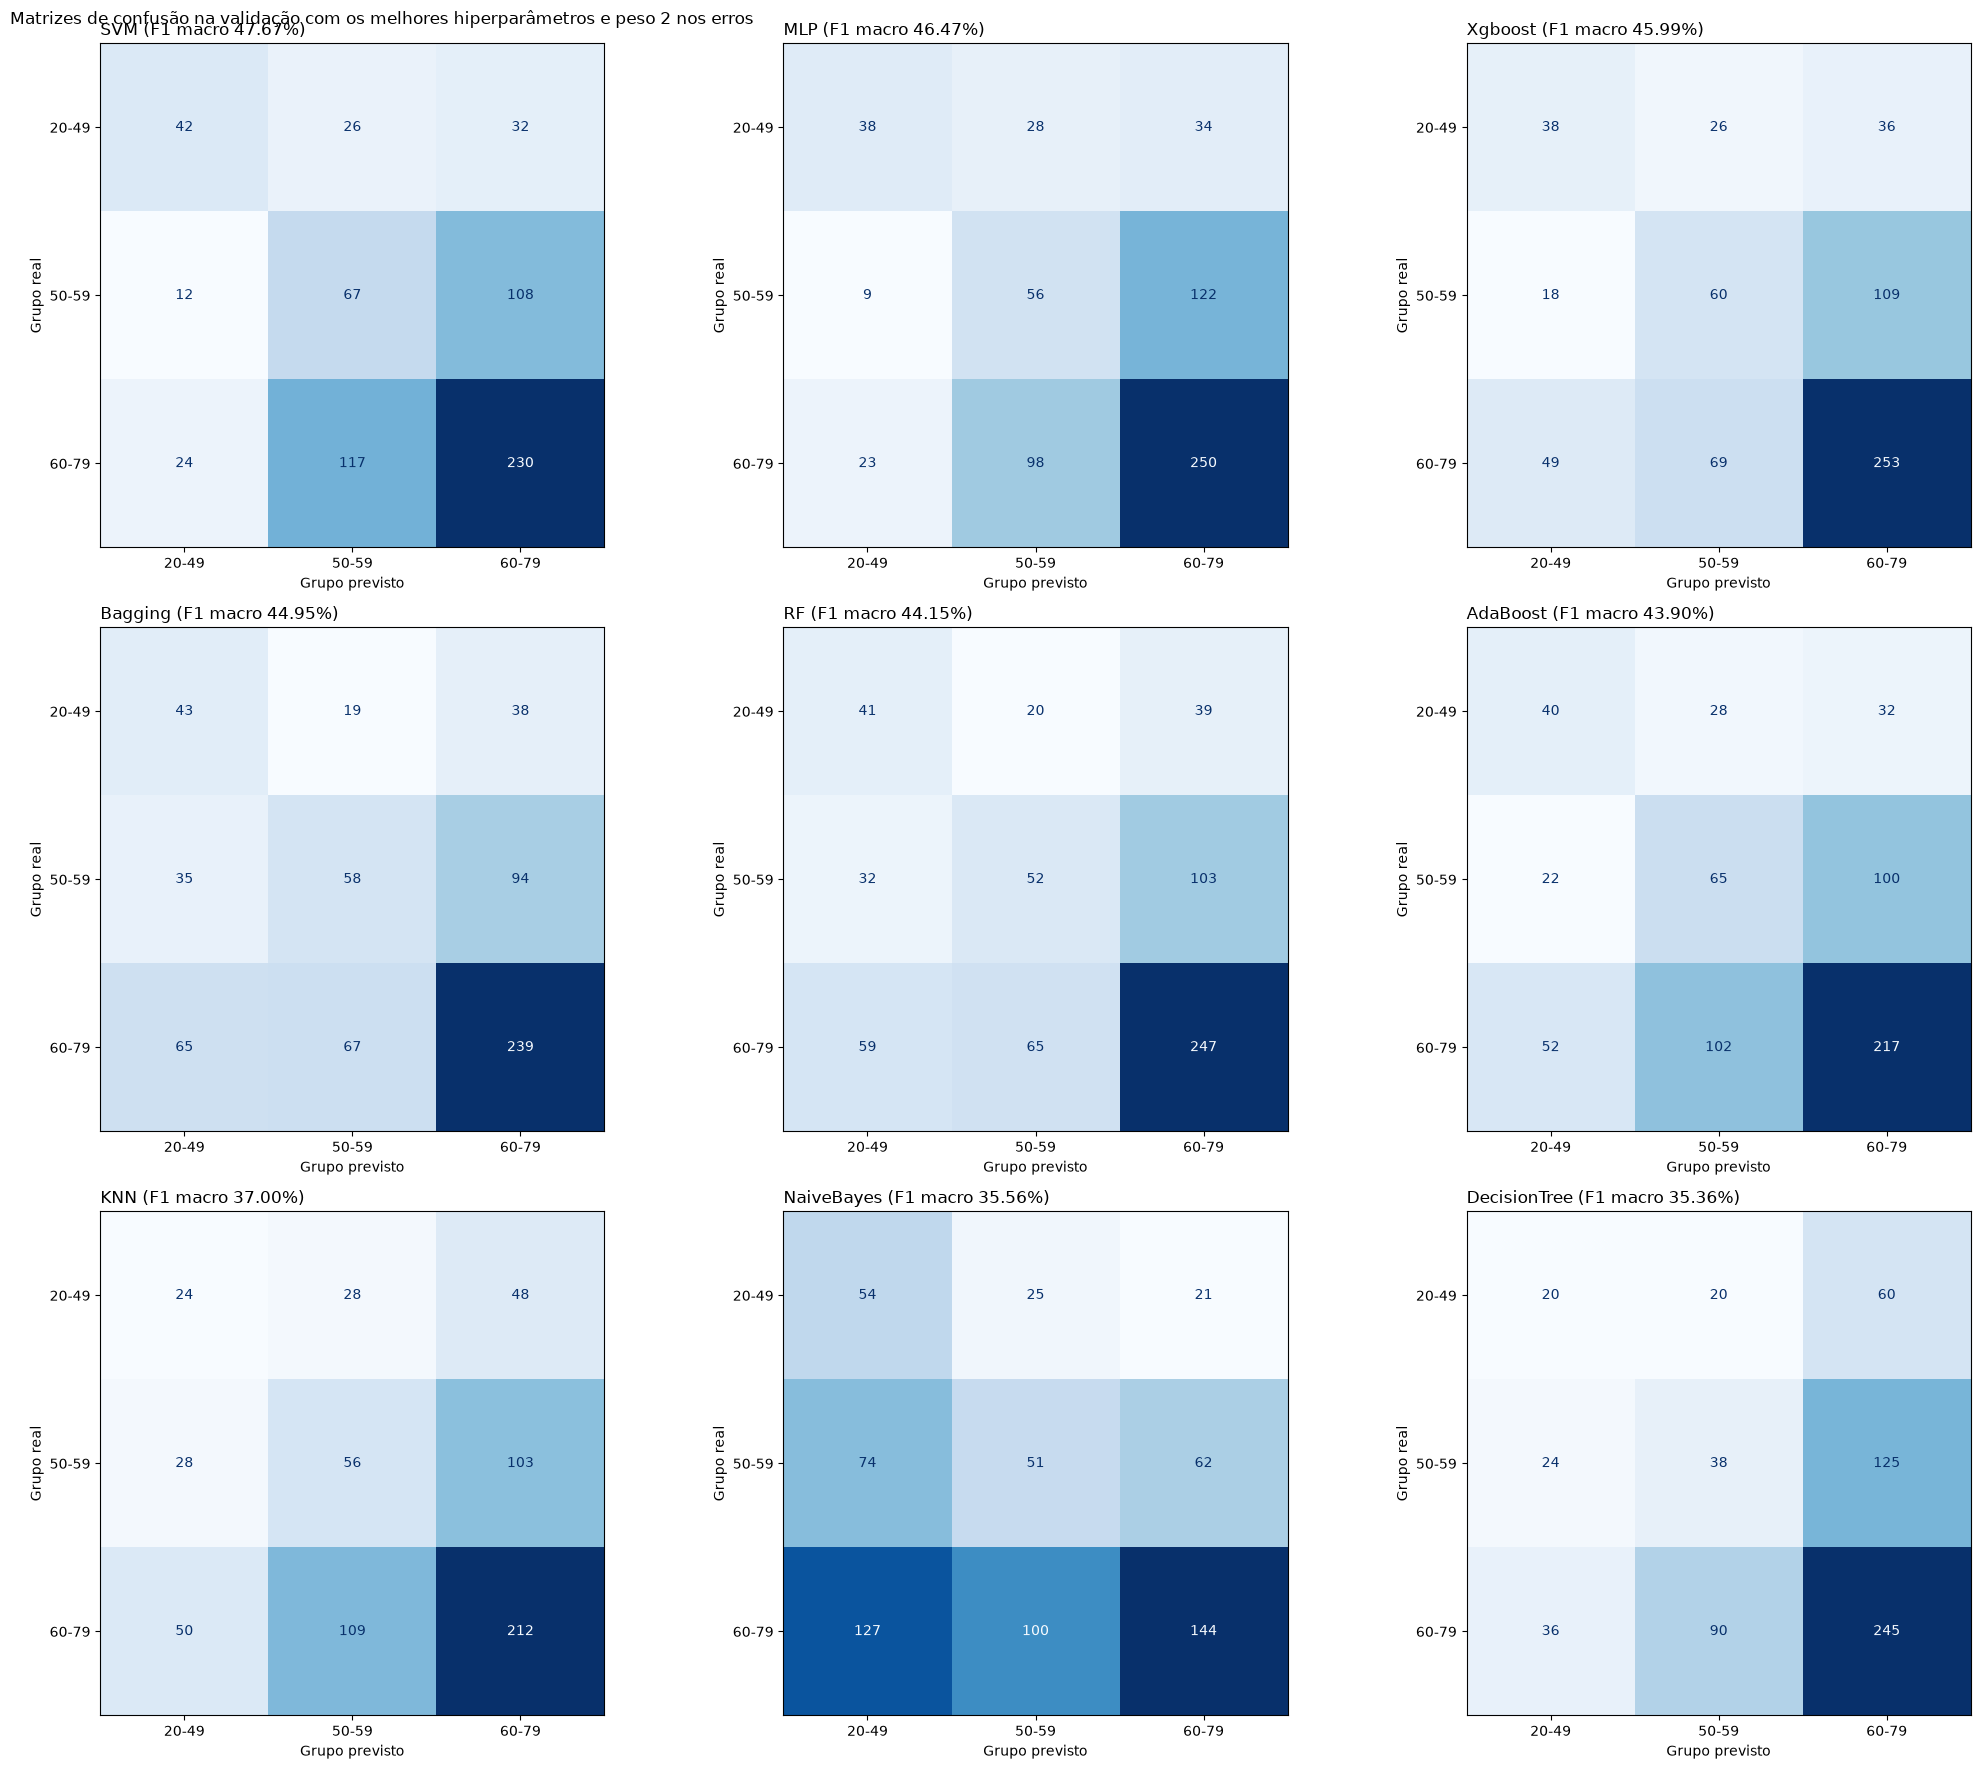

In [11]:
n_models = len(best_predictions)
n_cols = 3
fig, axes = plt.subplots(int(np.ceil(n_models / n_cols)), n_cols, figsize=(7 * n_cols, 6 * int(np.ceil(n_models / n_cols))))
for ax, name in zip(axes.flat, grid_results.columns):
    ConfusionMatrixDisplay.from_predictions(y_val, best_predictions[name], labels=sorted(GROUP_LABELS),
                                            display_labels=[GROUP_LABELS[code] for code in sorted(GROUP_LABELS)],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set(xlabel="Grupo previsto", ylabel="Grupo real")
    ax.set_title(f"{name} (F1 macro {grid_results.loc['F1 macro', name]:.2f}%)", loc="left")
for ax in list(axes.flat)[n_models:]:
    ax.axis("off")
fig.suptitle(f"Matrizes de confusão na validação com os melhores hiperparâmetros e peso {Config.MISCLASSIFIED_WEIGHT} nos erros", x=0.02, ha="left")
plt.tight_layout()
plt.show()